# GNSS tropospheric delay — a short introduction

**Learning goals:** understand the hydrostatic (“dry”) and wet components, convert zenith delay to slant delay, and calculate a simple example using the `dsoclasses` **GPT3 + GMF** functions.

No RINEX or SP3 files are needed. We use a sample station near Athens and an example epoch. The notebook is designed to be run **before** `gps_code_analysis.ipynb` and `tropo_zwd.ipynb`.


## 1. Why do GNSS signals experience tropospheric delay?

Neutral air slows a radio signal relative to propagation in vacuum. For a satellite above the horizon, the added path length (in metres) is **positive**. In a simplified code observation equation,

$$P = \rho + c(\delta t_r-\delta t_s) + T + I + \varepsilon,$$

where $T$ is the **tropospheric delay** and $I$ is the ionospheric term.

- **Hydrostatic (dry) component:** mostly due to the weight of dry air; closely related to surface pressure and relatively predictable.
- **Wet component:** due to water vapour; smaller, but more variable and harder to predict.

At an ordinary near-sea-level site, the total delay **at zenith** is often around **2–3 m**, with the hydrostatic term dominating. The delay grows at lower satellite elevations because the signal crosses a longer path through the atmosphere.

Unlike the first-order ionospheric delay, the neutral-atmosphere delay is approximately **non-dispersive** at GNSS microwave frequencies: it does not disappear in an ionosphere-free dual-frequency combination.

## 2. Zenith hydrostatic delay (ZHD) and zenith wet delay (ZWD)

We first compute the delays for a satellite **directly overhead**:

$$\mathrm{ZTD}=\mathrm{ZHD}+\mathrm{ZWD}.$$

Here ZTD means *zenith total delay*. A common model for ZHD is the Saastamoinen formula, using pressure $p$ (hPa), geodetic latitude $\varphi$ and ellipsoidal height $h$ (metres):

$$\mathrm{ZHD}\;\simeq\;\frac{0.0022768\,p}{1-0.00266\cos(2\varphi)-0.00000028\,h}.$$

For a **first example**, use *illustrative atmospheric values*, not measurements or GPT3 output. We will replace them with GPT3 values later. `dsoclasses` also implements an Askne–Nordius-based initial estimate of ZWD.

In [2]:
from datetime import datetime
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from dsoclasses.troposphere import gpt3, gmf
from dsoclasses.troposphere.tropo import tropo_delay
from dsoclasses.geodesy.transformations import ell2car

# A teaching example near Athens. Coordinates are GEODETIC and not a station solution.
latitude_deg = 38.0      # degrees north
longitude_deg = 23.7     # degrees east
height_m = 150.0         # metres ABOVE THE ELLIPSOID (not orthometric height)
epoch = datetime(2024, 1, 1, 12, 0, 0)  # one GNSS calendar epoch

# The library's trigonometric functions take RADIANS.
latitude = np.deg2rad(latitude_deg)
longitude = np.deg2rad(longitude_deg)

print(f"Position: {latitude_deg:.2f}° N, {longitude_deg:.2f}° E, h={height_m:.1f} m")
print(f"Epoch:    {epoch.isoformat(sep=' ')}")

Position: 38.00° N, 23.70° E, h=150.0 m
Epoch:    2024-01-01 12:00:00


In [3]:
# These are deliberately illustrative inputs (NOT a weather observation).
pressure_hpa = 1000.0   # total air pressure in hPa
vapour_hpa = 12.0       # water-vapour partial pressure in hPa
mean_temp_k = 275.0    # mean water-vapour temperature in kelvin
vapour_lapse = 2.0      # dimensionless water-vapour decrease parameter

# Reuse the project's model routines rather than duplicating their formulas.
zhd_demo = float(gpt3.saastamoinen_zhd(latitude, height_m, pressure_hpa))
zwd_demo = float(gpt3.askne_zwd(vapour_hpa, mean_temp_k, vapour_lapse))
ztd_demo = zhd_demo + zwd_demo

print('ILLUSTRATIVE ATMOSPHERE:')
print(f'ZHD = {zhd_demo:.4f} m')
print(f'ZWD = {zwd_demo:.4f} m')
print(f'ZTD = {ztd_demo:.4f} m')
assert 1.0 < zhd_demo < 3.5 and 0.0 < zwd_demo < 1.0

ILLUSTRATIVE ATMOSPHERE:
ZHD = 2.2784 m
ZWD = 0.1627 m
ZTD = 2.4411 m


## 3. Mapping functions: from zenith to a satellite elevation

The signal is rarely vertical. If $E$ is the satellite **elevation angle** (90° = zenith), the standard symmetric model is

$$\boxed{T(E)=m_h(E)\,\mathrm{ZHD}+m_w(E)\,\mathrm{ZWD}}$$

$m_h$ and $m_w$ are dimensionless **mapping functions**, normally close to 1 at zenith and larger at low elevations. A simple geometric approximation is $1/\sin E$, but proper mapping functions account for atmospheric structure and Earth curvature.

We will use **GMF** (*Global Mapping Function*), which returns separate hydrostatic and wet factors. In this library, `gmf.gmf(epoch, lat, lon, height, zenith_distance)` takes **zenith distance** in radians, not elevation; $\mathrm{ZD}=90^\circ-E$.

In [4]:
# Example satellite at an elevation of 30 degrees.
elevation_deg = 30.0
elevation = np.deg2rad(elevation_deg)
zenith_distance = np.pi / 2 - elevation

m_h, m_w = gmf.gmf(epoch, latitude, longitude, height_m, zenith_distance)
slant_h = float(m_h * zhd_demo)
slant_w = float(m_w * zwd_demo)
slant_total = slant_h + slant_w

print(f'Elevation angle: {elevation_deg:.1f}°')
print(f'GMF mapping factors: hydrostatic={m_h:.4f}, wet={m_w:.4f}')
print(f'Hydrostatic slant delay = {slant_h:.4f} m')
print(f'Wet slant delay         = {slant_w:.4f} m')
print(f'Total slant delay       = {slant_total:.4f} m')

# At a few elevation angles, compare GMF to the naive flat-atmosphere
# approximation 1/sin(E). Both factors are dimensionless.
print('\nElev.   1/sin(E)   GMF dry    GMF wet')
for angle_deg in (5.0, 10.0, 30.0, 90.0):
    angle_rad = np.deg2rad(angle_deg)
    dry_map, wet_map = gmf.gmf(epoch, latitude, longitude, height_m,
                                np.pi / 2 - angle_rad)
    print(f'{angle_deg:5.0f}°  {1 / np.sin(angle_rad):8.3f}   '
          f'{dry_map:8.3f}   {wet_map:8.3f}')

assert slant_total > ztd_demo

Elevation angle: 30.0°
GMF mapping factors: hydrostatic=1.9928, wet=1.9968
Hydrostatic slant delay = 4.5402 m
Wet slant delay         = 0.3249 m
Total slant delay       = 4.8651 m

Elev.   1/sin(E)   GMF dry    GMF wet
    5°    11.474     10.143     10.804
   10°     5.759      5.554      5.665
   30°     2.000      1.993      1.997
   90°     1.000      1.000      1.000


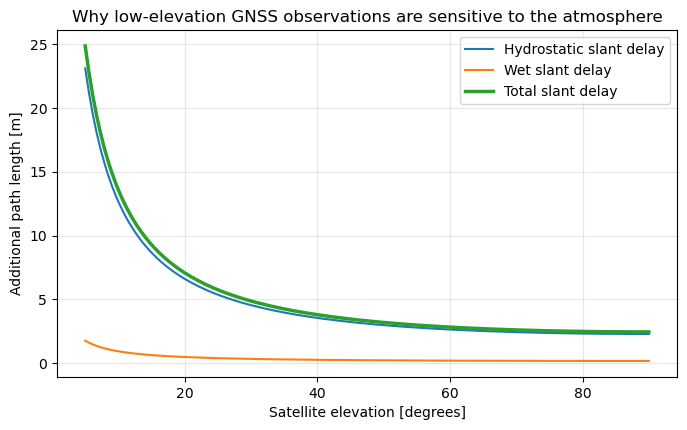

In [5]:
# The elevation-dependence is far more important than the (small) difference
# between m_h and m_w for this basic example.
elevations_deg = np.linspace(5.0, 90.0, 150)
hydrostatic_slant = []
wet_slant = []
map_h = []

for angle in elevations_deg:
    zd = np.pi / 2 - np.deg2rad(angle)
    mh, mw = gmf.gmf(epoch, latitude, longitude, height_m, zd)
    map_h.append(float(mh))
    hydrostatic_slant.append(float(mh * zhd_demo))
    wet_slant.append(float(mw * zwd_demo))

hydrostatic_slant = np.array(hydrostatic_slant)
wet_slant = np.array(wet_slant)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(elevations_deg, hydrostatic_slant, label='Hydrostatic slant delay')
ax.plot(elevations_deg, wet_slant, label='Wet slant delay')
ax.plot(elevations_deg, hydrostatic_slant + wet_slant,
        label='Total slant delay', linewidth=2.5)
ax.set(xlabel='Satellite elevation [degrees]', ylabel='Additional path length [m]',
       title='Why low-elevation GNSS observations are sensitive to the atmosphere')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 4. GPT3: where do the atmospheric inputs come from?

**GPT3** (*Global Pressure and Temperature 3*) is an empirical model, developed from atmospheric data. Given a **latitude, longitude, ellipsoidal height, epoch, and grid file**, it provides estimates such as:

| GPT3 output | Meaning | Unit |
|---|---|---|
| `p` | Air pressure at station height | hPa |
| `T` | Air temperature | °C |
| `e` | Water-vapour pressure | hPa |
| `Tm` | Mean water-vapour temperature | K |
| `la` | Water-vapour decrease parameter | dimensionless |

We use `p` to calculate ZHD, and `e`, `Tm`, `la` to obtain an **a priori ZWD**. GPT3 does **not** directly give a GNSS slant delay.

A small **four-node excerpt of the real 5° GPT3 grid** is supplied with this lesson. It is sufficient **only for coordinates inside 37.5°–42.5° N and 22.5°–27.5° E**. When available, the notebook prefers the complete `data/gpt3_5.grd` in your existing project. Source: [TU Wien VMF Data Server](https://vmf.geo.tuwien.ac.at/codes/gpt3_5.grd).

In [6]:
# Search for the full GPT3 grid in the usual project paths first.
# If it is not installed, use the small official-grid excerpt shipped with
# this teaching example. The excerpt is only suitable near Athens.

search_roots = [Path.cwd(), Path.cwd().parent,
                Path.cwd().parent.parent]

# Notebook launched from notebooks/gnss -> ../../data; other launch
# directories are handled too. Searching by explicit names avoids quietly
# loading an unrelated file.
full_candidates = [root / 'data' / 'gpt3_5.grd' for root in search_roots]
small_candidates = [root / 'data' / 'gpt3_5_athens_excerpt.grd'
                    for root in search_roots]
# Also allow the excerpt (or full grid) beside the notebook itself.
full_candidates += [root / 'gpt3_5.grd' for root in search_roots]
small_candidates += [root / 'gpt3_5_athens_excerpt.grd' for root in search_roots]

gpt3_grid = next((p.resolve() for p in full_candidates if p.is_file()), None)
using_excerpt = False
if gpt3_grid is None:
    gpt3_grid = next((p.resolve() for p in small_candidates if p.is_file()), None)
    using_excerpt = gpt3_grid is not None

if gpt3_grid is None:
    print('GPT3 grid not found. The illustrative example above still works.')
    print('To run the GPT3 example, put gpt3_5.grd in the project data folder,')
    print('or extract the bundled Athens-grid excerpt alongside this notebook.')
else:
    if using_excerpt and not (37.5 <= latitude_deg <= 42.5 and
                              22.5 <= longitude_deg <= 27.5):
        raise ValueError('The four-node teaching excerpt is only valid near Athens.')
    print(f'GPT3 source: {gpt3_grid}')
    print('Dataset:', 'ATHENS-ONLY EXCERPT' if using_excerpt else 'FULL GRID')

GPT3 source: /home/xanthos/Software/AcademicSoftware/data/gpt3_5.grd
Dataset: FULL GRID


In [7]:
# Repeat the whole calculation, now with REAL GPT3 model input rather
# than the arbitrary atmospheric values used in section 2.
if gpt3_grid is not None:
    # IMPORTANT: GPT3 expects (longitude, latitude), both in RADIANS.
    meteo = gpt3.gpt3(epoch, longitude, latitude, height_m, str(gpt3_grid))

    zhd_gpt3 = float(gpt3.saastamoinen_zhd(latitude, height_m, meteo['p']))
    zwd_gpt3 = float(gpt3.askne_zwd(meteo['e'], meteo['Tm'], meteo['la']))

    mh, mw = gmf.gmf(epoch, latitude, longitude, height_m,
                     np.pi / 2 - np.deg2rad(elevation_deg))
    slant_gpt3 = float(zhd_gpt3 * mh + zwd_gpt3 * mw)

    # Compare with the tested high-level wrapper, which receives ECEF XYZ.
    station_xyz = np.array(ell2car(latitude, longitude, height_m))
    slant_wrapper = tropo_delay(station_xyz, epoch, np.deg2rad(elevation_deg),
                                str(gpt3_grid))

    print(f'GPT3 pressure = {meteo["p"]:.2f} hPa; temperature = {meteo["T"]:.2f} °C')
    print(f'GPT3 water-vapour pressure = {meteo["e"]:.2f} hPa')
    print(f'ZHD = {zhd_gpt3:.4f} m; a priori ZWD = {zwd_gpt3:.4f} m')
    print(f'ZTD = {zhd_gpt3 + zwd_gpt3:.4f} m')
    print(f'Total delay at {elevation_deg:.0f}° = {slant_gpt3:.4f} m')
    print(f'Delay using tropo_delay wrapper = {slant_wrapper:.4f} m')
    assert np.isclose(slant_gpt3, slant_wrapper, atol=1e-8)
else:
    print('GPT3 numerical example skipped: no grid file was available.')

GPT3 pressure = 1003.92 hPa; temperature = 10.34 °C
GPT3 water-vapour pressure = 10.08 hPa
ZHD = 2.2873 m; a priori ZWD = 0.0907 m
ZTD = 2.3780 m
Total delay at 30° = 4.7391 m
Delay using tropo_delay wrapper = 4.7391 m


## 5. What changes when we use this in positioning?

A practical observation model often starts with

$$T(E) = m_h(E)\,\mathrm{ZHD}_{\mathrm{model}} +
           m_w(E)\,[\mathrm{ZWD}_{\mathrm{a\ priori}}+\Delta\mathrm{ZWD}].$$

- **ZHD** is usually modelled from measured or modelled pressure.
- **ZWD** can start from GPT3 but is frequently **estimated from GNSS observations** (especially with carrier phase), because water vapour changes rapidly.
- Use the **correct elevation angle**, consistent coordinate units (degrees vs radians), and the appropriate **time system**. In this notebook the epoch is a simple calendar label; a precise GNSS pipeline must keep GNSS time scales consistent.
- **Low elevations** amplify atmospheric modelling errors, antenna effects and multipath. We typically apply elevation weighting and/or a cutoff.
- Advanced positioning may also estimate **horizontal tropospheric gradients**. We neglect them here.

**Do not confuse the models:** GPT3 provides meteorology and also some coefficients used with *VMF3*. In this notebook, **GMF** supplies the mapping factors separately and does **not** consume GPT3's `ah` or `aw` coefficients.

The slant delay affects both GNSS code and carrier-phase geometric propagation; the ionosphere follows a different frequency-dependent model.

### Quick questions for students

1. Why is ZHD more predictable than ZWD?
2. Why is the slant delay greater for satellites near the horizon?
3. If we already calculate an a priori ZWD with GPT3, why might a PPP solution still estimate an additional wet-delay parameter?

**Further reading (optional):**
- [TU Wien VMF server — GPT3, GMF and VMF3 descriptions](https://vmf.geo.tuwien.ac.at/products.html)
- [Landskron & Böhm (2018), VMF3 and GPT3](https://doi.org/10.1007/s00190-017-1066-2)
- [Böhm et al. (2006), GMF](https://doi.org/10.1029/2005GL025546)

*Grid attribution:* The four GPT3 rows distributed with this tutorial are from the TU Wien VMF Data Server; please acknowledge TU Wien and ECMWF according to the [server's terms](https://vmf.geo.tuwien.ac.at/terms.html).